# 22. 최적 변수 조합 × 비지도 모델 탐색 (선택 과적합 방지)

**탐색 범위**: 변수 조합 12 × 모델 10 = **120개 설정** (모두 unlabeled로만 학습)

| 방법 | 고르는 데 쓰는 것 | 평가 | 의미 |
|---|---|---|---|
| **① 중첩 LORO** | 나머지 labeled Run의 라벨 | 빼둔 Run | '고르는 과정까지 포함한' 정직한 성능 |
| **② 가상 불량 주입** | unlabeled에 넣은 가상 이상 (라벨 X) | labeled 한 번 | 라벨 안 보고 고른 설정의 실제 성능 |
| (참고) 전체 그리드 | labeled 라벨 | 같은 labeled | 사후 비교 — 1등은 부풀려짐 |

**결론 내는 법**
- ①·②가 **같은 설정**을 고르고, 최종 모델보다 **CI상 좋음** → 교체
- 고른 설정이 Run마다 바뀌거나 '차이 없음' → **최종 모델 유지** (탐색해도 개선 없음 = 견고성 근거)

⏱ 첫 실행은 오래 걸림 (설정 120개 × 학습 2회 × 제품 2개, 대략 20~40분). 점수는 캐시에 저장 → 다시 열면 바로 표만 계산

In [1]:
import os
import pandas as pd
from search_final import (prepare_search, all_configs, run_scores, grid_table, select_by_synthetic,
                          synthetic_validity, nested_loro, plot_grid, plot_syn_vs_real, INJ_TYPES)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 45)
OUT = './outputs/search_final'
os.makedirs(OUT, exist_ok=True)

DATA = {p: prepare_search(p) for p in ['cn7', 'rg3']}

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:73: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  np.random.default_rng(seed).shuffle(runs)


[cn7] reference 전체 5,179 / 학습용 1,465 / 주입용 3,714샷 (Run 1개), 유형별 주입 샷: 미성형형 92, 쿠션부족 92, 계량지연 92, 점도상승 92, 열드리프트 930, 단일 변수 튐 92


c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:73: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  np.random.default_rng(seed).shuffle(runs)


[rg3] reference 전체 4,359 / 학습용 2,327 / 주입용 2,032샷 (Run 2개), 유형별 주입 샷: 미성형형 48, 쿠션부족 48, 계량지연 48, 점도상승 48, 열드리프트 500, 단일 변수 튐 49


## 0. 가상 불량이 제대로 들어갔나
주입 샷과 정상 샷의 원값 차이 (주입 샷 − 주입 안 된 샷 중앙값, 단위 = 원값). 방향이 설계와 맞는지 확인

In [2]:
from final_model import raw
for p, D in DATA.items():
    rows = []
    for t, f in D['inj'].items():
        vs = INJ_TYPES[t] or {}
        for v in vs:
            c = raw(v)
            rows.append({'유형': t, '변수': v, '방향': '+' if vs[v] > 0 else '−',
                         '주입 샷 수': int(f['inj'].sum()),
                         '차이(주입 − 정상 중앙값)': f.loc[f['inj'] == 1, c].median() - f.loc[f['inj'] == 0, c].median(),
                         '정상 Run 내 σ': D['sigma'][v][0]})
    print(p.upper()); display(pd.DataFrame(rows).round(4))

CN7


,유형,변수,방향,주입 샷 수,차이(주입 − 정상 중앙값),정상 Run 내 σ
0,미성형형(충전↓·속도↑·쿠션↓),Filling_Time,−,92,-0.06,0.0148
1,미성형형(충전↓·속도↑·쿠션↓),Injection_Time,−,92,-0.06,0.0148
2,미성형형(충전↓·속도↑·쿠션↓),Max_Injection_Speed,+,92,0.60,0.1483
3,미성형형(충전↓·속도↑·쿠션↓),Cushion_Position,−,92,-0.04,0.0100
4,쿠션부족(재료 부족),Cushion_Position,−,92,-0.04,0.0100
5,쿠션부족(재료 부족),Max_Injection_Pressure,+,92,0.30,0.1000
6,계량지연,Plasticizing_Time,+,92,0.25,0.0593
7,계량지연,Average_Back_Pressure,+,92,0.30,0.1483
8,점도상승(압력↑·속도↓),Max_Injection_Pressure,+,92,0.50,0.1000
9,점도상승(압력↑·속도↓),Max_Switch_Over_Pressure,+,92,1.40,0.2965


RG3


,유형,변수,방향,주입 샷 수,차이(주입 − 정상 중앙값),정상 Run 내 σ
0,미성형형(충전↓·속도↑·쿠션↓),Filling_Time,−,48,-0.04,0.0100
1,미성형형(충전↓·속도↑·쿠션↓),Injection_Time,−,48,-0.04,0.0100
2,미성형형(충전↓·속도↑·쿠션↓),Max_Injection_Speed,+,48,0.40,0.1000
3,미성형형(충전↓·속도↑·쿠션↓),Cushion_Position,−,48,-0.06,0.0148
4,쿠션부족(재료 부족),Cushion_Position,−,48,-0.06,0.0148
5,쿠션부족(재료 부족),Max_Injection_Pressure,+,48,0.30,0.1483
6,계량지연,Plasticizing_Time,+,48,0.10,0.0222
7,계량지연,Average_Back_Pressure,+,48,0.40,0.2224
8,점도상승(압력↑·속도↓),Max_Injection_Pressure,+,48,0.55,0.1483
9,점도상승(압력↑·속도↓),Max_Switch_Over_Pressure,+,48,0.70,0.1483


## 1. 점수 계산 (120개 설정)

In [3]:
S = run_scores(DATA, all_configs(), cache=f'{OUT}/scores.pkl')
G = grid_table(DATA, S)
G.to_csv(f'{OUT}/grid_all.csv', index=False, encoding='utf-8-sig')

[cn7] 설정 120개 점수 계산


c:\anaconda\envs\kamp\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


    10/120 설정 완료 (20초)


c:\anaconda\envs\kamp\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


    20/120 설정 완료 (54초)
    30/120 설정 완료 (62초)
    40/120 설정 완료 (67초)
    50/120 설정 완료 (72초)
    60/120 설정 완료 (77초)
    70/120 설정 완료 (83초)


...

    120/120 설정 완료 (113초)
[rg3] 설정 120개 점수 계산
    10/120 설정 완료 (5초)
    20/120 설정 완료 (8초)
    30/120 설정 완료 (10초)
    40/120 설정 완료 (15초)
    50/120 설정 완료 (20초)
    60/120 설정 완료 (25초)
    70/120 설정 완료 (30초)


c:\anaconda\envs\kamp\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


    80/120 설정 완료 (36초)
    90/120 설정 완료 (41초)
    100/120 설정 완료 (46초)
    110/120 설정 완료 (51초)


c:\anaconda\envs\kamp\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


    120/120 설정 완료 (58초)


## 2. 방법 ② 가상 불량 주입으로 선택
가상불량 평균 AP 상위 5개 + 최종 모델 → labeled로 **한 번** 평가, 최종 모델 대비 ΔAP 판정

In [4]:
SEL2 = select_by_synthetic(DATA, S, top=5)
SEL2.to_csv(f'{OUT}/select_synthetic.csv', index=False, encoding='utf-8-sig')
display(SEL2.round(3))

,제품,설정,①AP,①유의,①상위10%,②AP,②AP_lo,②AP_hi,②Run별 상위10%,②AP_가스,②AP_미성형,가상 순위,가상불량 평균AP,①ΔAP(vs 최종),①Δ CI,①판정,②ΔAP(vs 최종),②Δ CI,②판정
0,cn7,event (8) | ocsvm,0.381,O,8/17,0.097,0.013,0.338,5/15,0.008,0.309,1,0.823,0.008,"[-0.004, 0.030]",차이 없음,-0.047,"[-0.109, 0.010]",차이 없음
1,cn7,free − summary | autoenc,0.370,O,6/17,0.138,0.011,0.350,3/15,0.007,0.480,2,0.820,-0.003,"[-0.014, 0.004]",차이 없음,-0.074,"[-0.137, 0.002]",차이 없음
2,cn7,event+summary (10) | ocsvm,0.386,O,8/17,0.143,0.014,0.366,5/15,0.009,0.481,3,0.817,0.013,"[-0.003, 0.045]",차이 없음,-0.046,"[-0.108, 0.012]",차이 없음
3,cn7,free − thermal | ocsvm,0.384,O,8/17,0.142,0.012,0.365,5/15,0.008,0.481,4,0.814,0.012,"[-0.004, 0.044]",차이 없음,-0.047,"[-0.108, 0.010]",차이 없음
4,cn7,event+summary (10) | gmm,0.377,O,8/17,0.214,0.010,0.420,4/15,0.008,0.751,5,0.814,0.004,"[-0.008, 0.027]",차이 없음,0.002,"[-0.007, 0.019]",차이 없음
5,cn7,"free (17, 최종) | maha",0.373,O,8/17,0.212,0.011,0.416,4/15,0.007,0.751,57,0.567,NaN,NaN,(최종 모델),NaN,NaN,(최종 모델)
6,rg3,free + level (31) | pca,0.027,-,4/25,0.068,0.048,0.115,5/32,0.052,0.024,1,0.472,0.004,"[-0.003, 0.017]",차이 없음,0.004,"[-0.014, 0.028]",차이 없음
7,rg3,event (8) | ocsvm,0.028,-,4/25,0.065,0.046,0.110,5/32,0.051,0.022,2,0.471,0.004,"[-0.010, 0.028]",차이 없음,0.002,"[-0.030, 0.038]",차이 없음
8,rg3,event+summary (10) | autoenc,0.028,-,3/25,0.060,0.047,0.111,3/32,0.044,0.027,3,0.449,0.004,"[-0.011, 0.030]",차이 없음,-0.004,"[-0.041, 0.037]",차이 없음
9,rg3,event+summary (10) | ocsvm,0.023,-,3/25,0.054,0.042,0.089,4/32,0.041,0.019,4,0.446,-0.001,"[-0.015, 0.013]",차이 없음,-0.009,"[-0.041, 0.017]",차이 없음


### 2-1. 가상 불량 성능이 실제 성능을 예측하나 (방법 ②의 타당성)
ρ가 양수이고 유의하면 → 가상 불량으로 고르는 게 의미 있음 / 0 근처면 → 가상 불량이 실제 불량과 닮지 않음

,제품,실제 지표,Spearman ρ,p
0,cn7,①AP,0.739,0.000
1,cn7,②AP,0.722,0.000
2,cn7,②AP_미성형,0.692,0.000
3,cn7,②AP_가스,0.223,0.014
4,rg3,①AP,0.231,0.011
5,rg3,②AP,-0.420,0.000
6,rg3,②AP_미성형,-0.255,0.005
7,rg3,②AP_가스,-0.372,0.000


c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:378: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:378: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:378: UserWarning: Glyph 48520 (\N{HANGUL SYLLABLE BUL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:378: UserWarning: Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:378: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEO

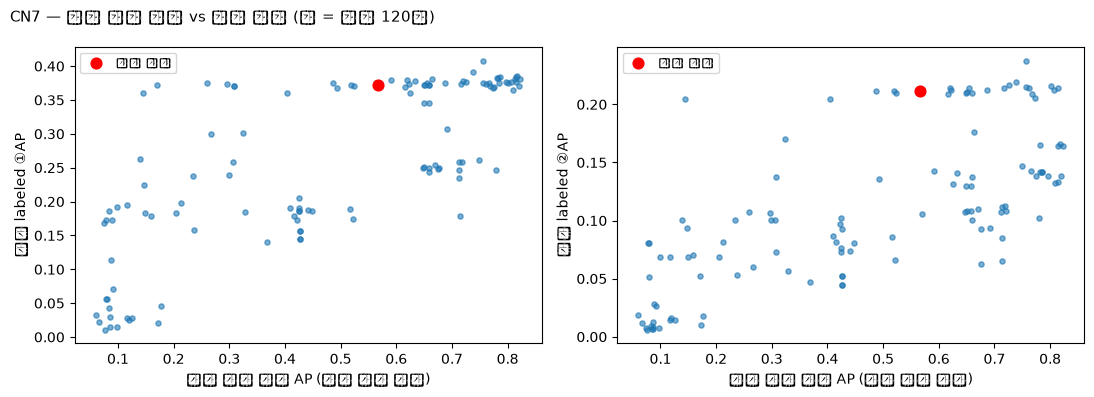

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:378: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:378: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:378: UserWarning: Glyph 48520 (\N{HANGUL SYLLABLE BUL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:378: UserWarning: Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:378: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEO

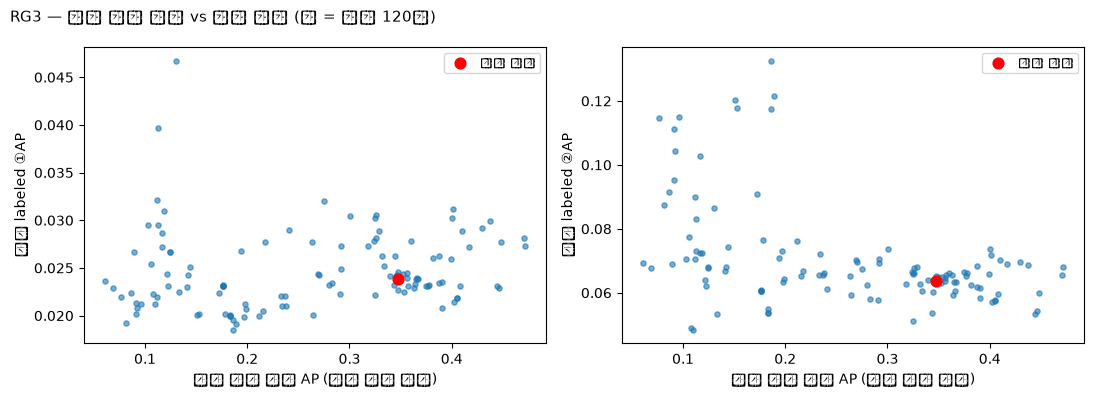

In [5]:
display(synthetic_validity(G).round(3))
for p in ['cn7', 'rg3']:
    plot_syn_vs_real(G, p, save=f'{OUT}/syn_vs_real_{p}.png')

## 3. 방법 ① 중첩 LORO
- **바깥 AP(탐색 포함)** vs **최종 모델 AP(고정)**: 탐색이 실제로 도움이 되나
- **Run별 선택 설정**: 빼는 Run마다 다른 설정이 뽑히면 = 선택이 불안정 (데이터가 선택을 뒷받침 못함)

In [6]:
N1, PICK = nested_loro(DATA, S)
N1.to_csv(f'{OUT}/nested_summary.csv', index=False, encoding='utf-8-sig')
PICK.to_csv(f'{OUT}/nested_picks.csv', index=False, encoding='utf-8-sig')
display(N1.round(3))
display(PICK.round(3))

,제품,바깥 AP(탐색 포함),최종 모델 AP(고정),ΔAP,Δ CI,판정,Run별 상위10%(탐색),Run별 상위10%(최종),선택된 서로 다른 설정 수
0,cn7,0.248,0.212,0.037,"[0.005, 0.105]",최종 모델보다 좋음,5/15,4/15,2
1,rg3,0.070,0.064,0.006,"[-0.045, 0.093]",차이 없음,3/32,3/32,3


,제품,빼둔 Run,빼둔 Run 불량,안쪽 불량,선택 설정,안쪽 AP(선택),안쪽 AP(최종 모델)
0,cn7,cn7_R1,14,1,raw_all (원값 21) | gmm,0.004,0.001
1,cn7,cn7_R2,0,15,event (8) | pca,0.247,0.215
2,cn7,cn7_R3,0,15,event (8) | pca,0.243,0.214
3,cn7,cn7_R4,0,15,event (8) | pca,0.242,0.213
4,cn7,cn7_R5,0,15,event (8) | pca,0.247,0.214
5,cn7,cn7_R6,1,14,event (8) | pca,0.257,0.229
6,rg3,rg3_R1,0,32,free + level (31) | iforest,0.135,0.068
7,rg3,rg3_R2,5,27,free + level (31) | iforest,0.152,0.073
8,rg3,rg3_R3,10,22,free + level (31) | iforest,0.170,0.064
9,rg3,rg3_R4,4,28,free + level (31) | iforest,0.140,0.060


## 4. (참고) 전체 그리드 — 사후 비교
⚠ 같은 labeled로 보고 고른 1등이라 성능이 부풀려짐. **결정에 쓰지 말고** 경향 파악용

In [7]:
for p in ['cn7', 'rg3']:
    print(p.upper(), '— ②AP 상위 10')
    display(G[G['제품'] == p].sort_values('②AP', ascending=False).head(10)
            [['변수 조합', '모델', '①AP', '②AP', '②AP_미성형', '②AP_가스', '가상불량 평균AP', '순위(가상)']].round(3))

CN7 — ②AP 상위 10


,변수 조합,모델,①AP,②AP,②AP_미성형,②AP_가스,가상불량 평균AP,순위(가상)
35,event (8),pca,0.408,0.238,0.751,0.021,0.756,21
75,free − summary,pca,0.391,0.220,0.751,0.012,0.738,24
45,event+summary (10),pca,0.376,0.217,0.751,0.010,0.725,25
48,event+summary (10),autoenc,0.376,0.216,0.751,0.009,0.801,9
95,free − flow,pca,0.375,0.215,0.751,0.009,0.756,22
85,free − thermal,pca,0.374,0.214,0.751,0.008,0.717,28
97,free − flow,gmm,0.380,0.214,0.751,0.010,0.620,53
91,free − flow,maha_emp,0.375,0.214,0.751,0.009,0.655,44
5,"free (17, 최종)",pca,0.374,0.214,0.751,0.009,0.761,20
47,event+summary (10),gmm,0.377,0.214,0.751,0.008,0.814,5


RG3 — ②AP 상위 10


,변수 조합,모델,①AP,②AP,②AP_미성형,②AP_가스,가상불량 평균AP,순위(가상)
234,free + level (31),iforest,0.020,0.133,0.025,0.142,0.186,79
141,level (원값 13+흐름저항),maha_emp,0.019,0.121,0.042,0.110,0.189,77
137,raw_all (원값 21),gmm,0.020,0.120,0.039,0.110,0.150,90
147,level (원값 13+흐름저항),gmm,0.020,0.118,0.036,0.109,0.153,89
131,raw_all (원값 21),maha_emp,0.018,0.118,0.038,0.108,0.186,78
140,level (원값 13+흐름저항),maha,0.021,0.115,0.029,0.111,0.096,111
144,level (원값 13+흐름저항),iforest,0.022,0.115,0.038,0.100,0.076,118
130,raw_all (원값 21),maha,0.020,0.111,0.029,0.106,0.091,114
231,free + level (31),maha_emp,0.021,0.104,0.036,0.088,0.093,112
132,raw_all (원값 21),knn,0.029,0.103,0.024,0.103,0.117,101


c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 55120 (\N{HANGUL SYLLABLE HEU

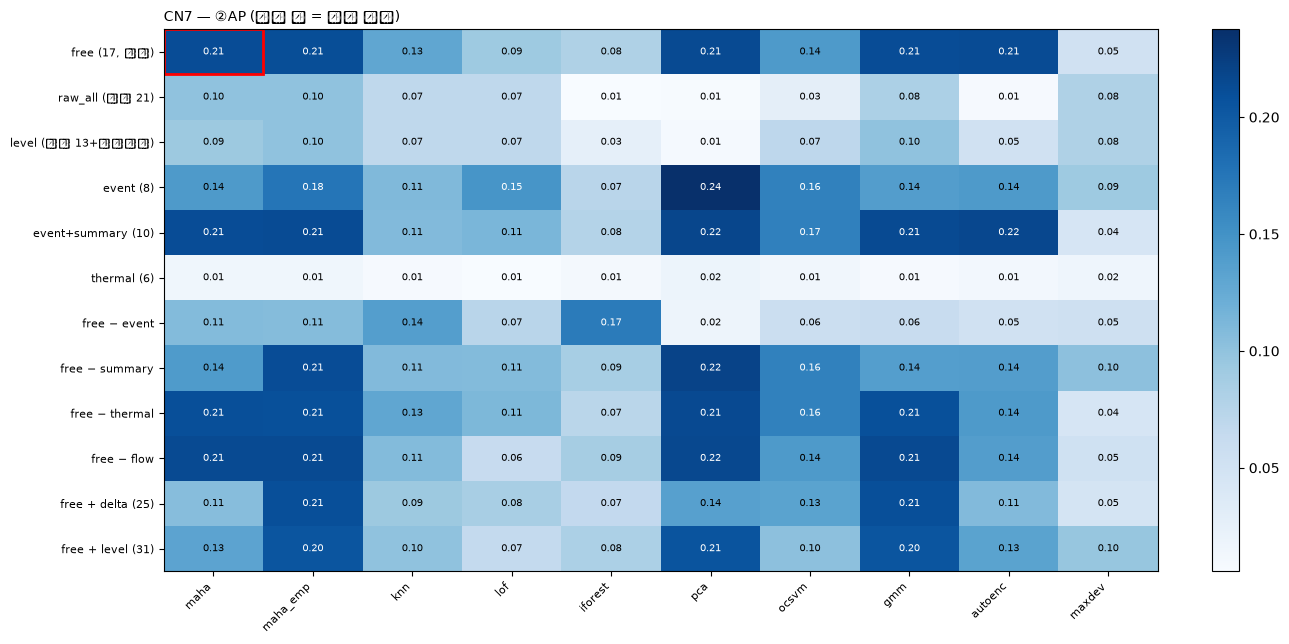

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 55120 (\N{HANGUL SYLLABLE HEU

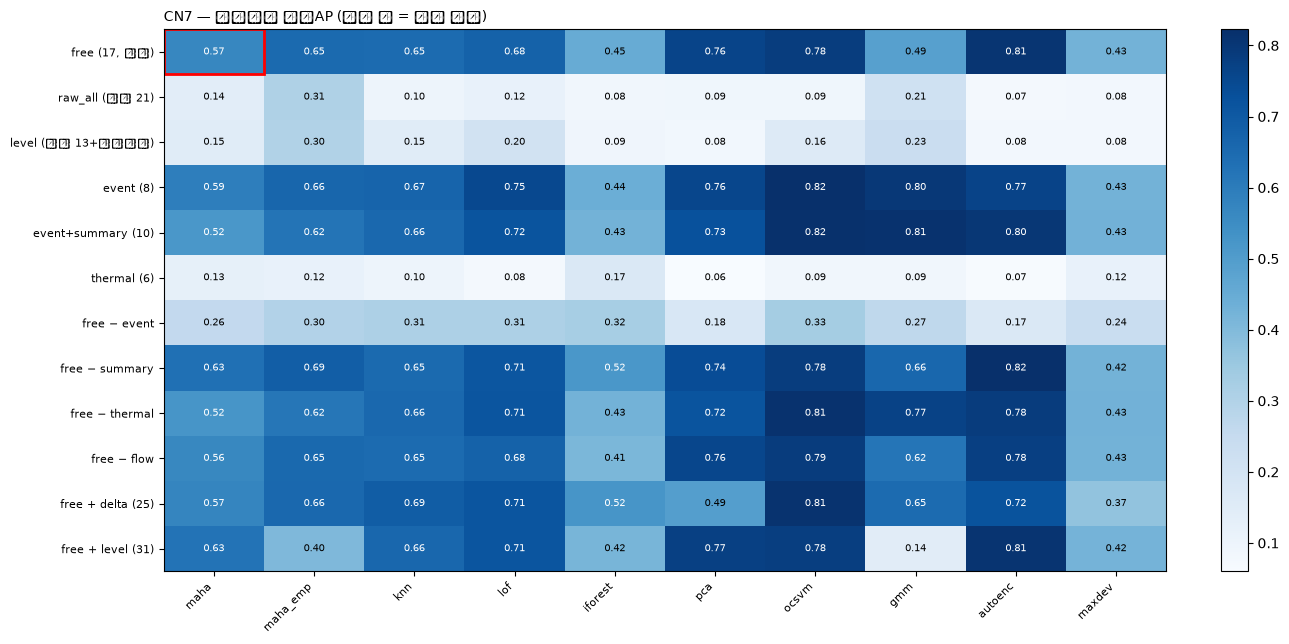

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 55120 (\N{HANGUL SYLLABLE HEU

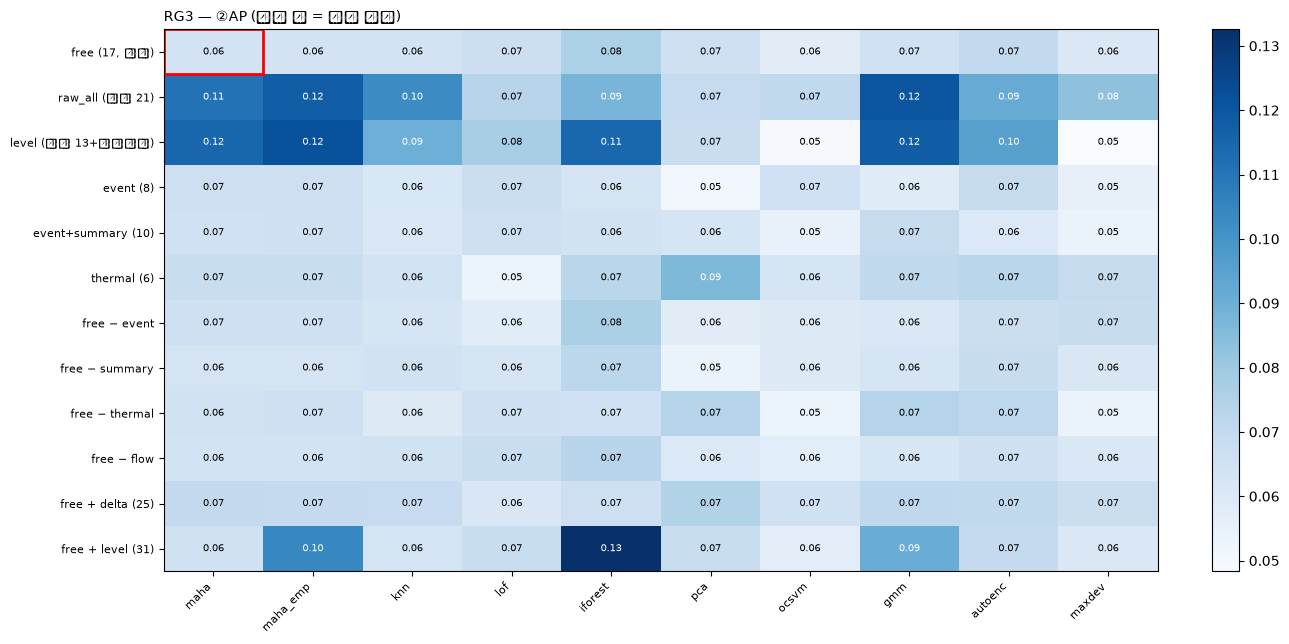

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\search_final.py:362: UserWarning: Glyph 55120 (\N{HANGUL SYLLABLE HEU

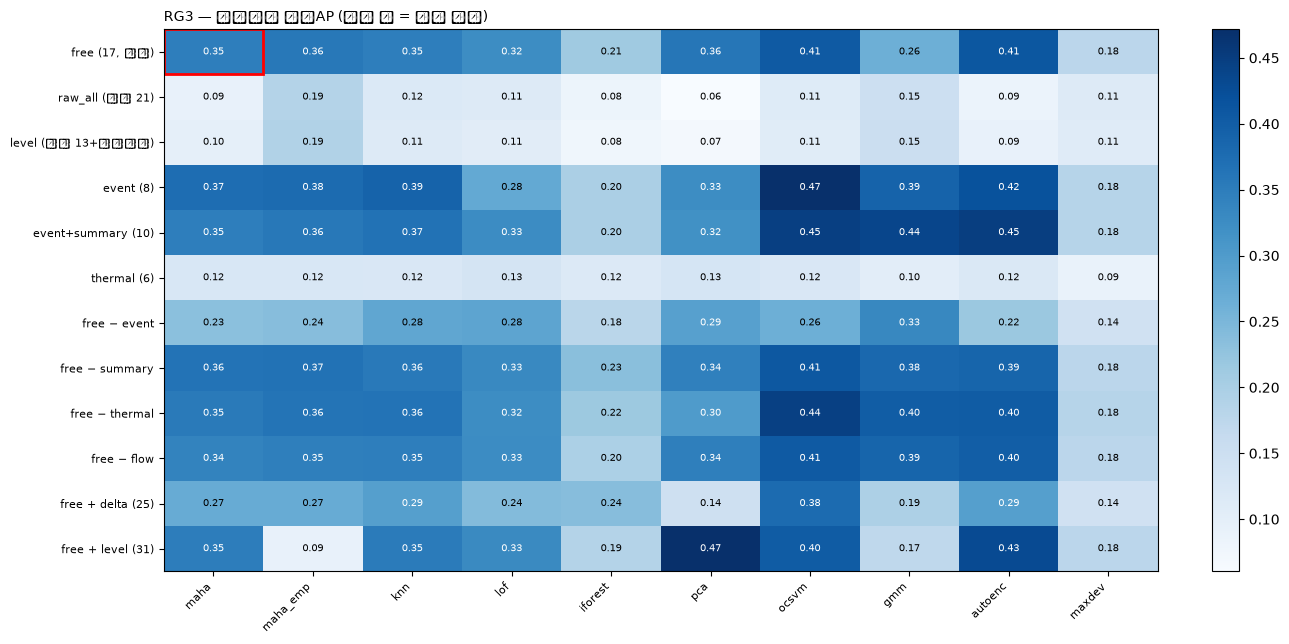

In [8]:
for p in ['cn7', 'rg3']:
    plot_grid(G, p, '②AP', save=f'{OUT}/grid_AP2_{p}.png')
    plot_grid(G, p, '가상불량 평균AP', save=f'{OUT}/grid_syn_{p}.png')

## 5. 결론 정리 (돌린 뒤 채우기)
| 질문 | 결과 |
|---|---|
| ② 가상 불량 1등 설정 / labeled 성능 / 최종 모델 대비 | |
| 가상 불량 ↔ 실제 성능 상관 (타당성) | |
| ① 중첩 LORO: 탐색 포함 AP vs 최종 모델 AP | |
| ① Run별 선택이 안정적인가 | |
| **최종 결정** (교체 / 유지) | |